In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("xgboost",   "xgboost==2.0.3",        "xgboost==2.0.3"),
    ("tensorflow", "tensorflow==2.11.0",    "tensorflow==2.16.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


# B6: Sử dụng học sâu RNN để phát hiện tấn công mạng

## Import các thư viện

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📦 IMPORT THƯ VIỆN CHO MACHINE LEARNING + DEEP LEARNING PIPELINE
# ═══════════════════════════════════════════════════════════════════════════════

# --------------------------
# Data handling & numerical computation
# --------------------------
import pandas as pd              # xử lý dữ liệu dạng bảng (DataFrame)
import numpy as np               # tính toán số học, vector/matrix
import re                        # xử lý regex (text cleaning nếu cần)
import warnings                  # quản lý cảnh báo
from pathlib import Path         # xử lý đường dẫn file an toàn đa hệ điều hành
from urllib.parse import unquote # decode URL encoding (nếu dataset có URL)

# --------------------------
# Visualization
# --------------------------
import matplotlib.pyplot as plt  # vẽ biểu đồ

# Tắt warning để output gọn hơn trong notebook
warnings.filterwarnings("ignore")


# --------------------------
# Scikit-learn (Machine Learning utilities)
# --------------------------
from sklearn.model_selection import train_test_split   # chia train/test
from sklearn.preprocessing import StandardScaler        # chuẩn hóa dữ liệu
from sklearn.metrics import (
    accuracy_score,           # độ chính xác
    f1_score,                 # F1-score (quan trọng với imbalance)
    precision_score,          # precision
    recall_score,             # recall
    classification_report,    # báo cáo chi tiết
    confusion_matrix,         # ma trận nhầm lẫn
    roc_auc_score,            # AUC score
    balanced_accuracy_score,  # accuracy cân bằng
    roc_curve,                # ROC curve
    ConfusionMatrixDisplay    # vẽ confusion matrix
)

# --------------------------
# TensorFlow / Keras (Deep Learning)
# --------------------------
import tensorflow as tf
from tensorflow import keras

from tensorflow.keras.preprocessing.text import Tokenizer   # text → token
from tensorflow.keras.preprocessing.sequence import pad_sequences  # padding sequence

from tensorflow.keras import layers, callbacks, Model
from tensorflow.keras.layers import (
    Concatenate,
    Input,
    Dense,
    Dropout
)

# --------------------------
# XGBoost (Gradient Boosting for tabular data)
# --------------------------
import xgboost as xgb


# ═══════════════════════════════════════════════════════════════════════════════
# 🎯 REPRODUCIBILITY (CỐ ĐỊNH KẾT QUẢ THÍ NGHIỆM)
# ═══════════════════════════════════════════════════════════════════════════════

RANDOM_STATE = 42  # seed chung cho toàn bộ pipeline

# đảm bảo kết quả có thể tái lập
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)


# ═══════════════════════════════════════════════════════════════════════════════
# 📁 DATASET PATH CONFIGURATION
# ═══════════════════════════════════════════════════════════════════════════════

# Đường dẫn dataset tương đối (portable trên mọi máy)
DATA_PATH = Path.cwd().parent / "Dataset" / "capec_small_multilabel2.csv"

## 1. Đọc dữ liệu

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 📥 1. ĐỌC DỮ LIỆU
# ═══════════════════════════════════════════════════════════════════════════════

# Đọc file CSV từ đường dẫn DATA_PATH
# low_memory=False:
#   - tránh cảnh báo dtype không đồng nhất
#   - đảm bảo pandas xử lý toàn bộ file một lần
df = pd.read_csv(DATA_PATH, low_memory=False)

# In kích thước dataset
# format: (số dòng, số cột)
print(f"Dataset shape: {df.shape}")

Dataset shape: (10000, 41)


## 2. Tiền xử lý URL 

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🌐 2. TIỀN XỬ LÝ URL + TOKENIZATION (CHAR-LEVEL)
# Mục tiêu:
# - Chuẩn hóa URL để giảm nhiễu
# - Biến URL thành chuỗi ký tự có cấu trúc ổn định hơn
# - Chuẩn bị đầu vào cho mô hình deep learning (LSTM/CNN)
# ═══════════════════════════════════════════════════════════════════════════════

def advanced_preprocess_url(url: str) -> str:
    """
    Chuẩn hóa URL để giảm biến thiên không cần thiết:

    Steps:
      1. Decode URL encoding
      2. Lowercase
      3. Loại bỏ protocol (http/https/ftp)
      4. Chuẩn hóa IP → <IP>
      5. Chuẩn hóa số → <NUM>
      6. Chuẩn hóa domain → <DOMAIN>
      7. Loại bỏ tracking parameters (utm_*)
    """

    try:
        url = unquote(url)  # decode URL encoding (%20 → space)
    except:
        pass

    # chuyển về chữ thường để giảm sparsity
    url = url.lower()

    # loại bỏ scheme (http://, https://, ftp://)
    url = re.sub(r"^[a-z]+://", "", url)

    # thay IP address bằng token <IP>
    url = re.sub(r"\b(?:\d{1,3}\.){3}\d{1,3}\b", "<IP>", url)

    # thay mọi số thành <NUM>
    url = re.sub(r"\d+", "<NUM>", url)

    # thay domain (example.com, abc.xyz.vn) thành <DOMAIN>
    url = re.sub(r"([a-z0-9\-]+\.)+[a-z]{2,}", "<DOMAIN>", url)

    # loại bỏ tracking parameters (utm_source, utm_medium,...)
    url = re.sub(r"utm_[a-z_]+=[^&]*&?", "", url)

    # xóa ký tự & dư ở cuối
    url = re.sub(r"&$", "", url)

    return url


# ═══════════════════════════════════════════════════════════════════════════════
# 📥 LẤY DỮ LIỆU URL THÔ
# ═══════════════════════════════════════════════════════════════════════════════

raw_urls = df["request_http_request"].astype(str)

# áp dụng preprocessing cho toàn bộ dataset
processed_urls = raw_urls.apply(advanced_preprocess_url)


# ═══════════════════════════════════════════════════════════════════════════════
# 🔤 TOKENIZATION CHAR-LEVEL
# ═══════════════════════════════════════════════════════════════════════════════

# MAX_URL_LEN:
# - giới hạn độ dài chuỗi đầu vào
# - tránh sequence quá dài gây tốn tài nguyên
MAX_URL_LEN = 400

# Tokenizer ở cấp ký tự (char-level)
# mỗi ký tự → một token (a, b, c, <, >, /, ...)
tokenizer = Tokenizer(
    char_level=True,   # quan trọng: không phải word-level
    filters="",        # không loại bỏ ký tự nào
    lower=False        # đã xử lý lowercase ở bước trước
)

# xây dựng vocabulary từ dữ liệu
tokenizer.fit_on_texts(processed_urls)

# kích thước từ điển
VOCAB_SIZE = len(tokenizer.word_index) + 1

# embedding dimension (cho neural network)
EMBED_DIM = 128


# ═══════════════════════════════════════════════════════════════════════════════
# 🔢 CHUYỂN URL → SEQUENCE
# ═══════════════════════════════════════════════════════════════════════════════

# chuyển mỗi URL thành dãy số (token id)
sequences = tokenizer.texts_to_sequences(processed_urls)

# padding để đảm bảo cùng độ dài MAX_URL_LEN
X_seq = pad_sequences(
    sequences,
    maxlen=MAX_URL_LEN,
    padding="post",      # thêm 0 vào cuối chuỗi
    truncating="post",   # cắt nếu quá dài
    value=0              # padding token
)

# kiểm tra kết quả
print(f"X_seq shape: {X_seq.shape} | Vocab size: {VOCAB_SIZE}")

X_seq shape: (10000, 400) | Vocab size: 70


## 3. Trích xuất đặc trưng

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🧠 3. TRÍCH XUẤT ĐẶC TRƯNG (HAND-CRAFTED FEATURES)
# Mục tiêu:
# - Biến HTTP log thô → vector đặc trưng có ý nghĩa
# - Kết hợp knowledge cybersecurity + statistical features
# - Phục vụ các mô hình ML truyền thống (XGBoost, RF, LR)
# ═══════════════════════════════════════════════════════════════════════════════


def extract_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Trích xuất >35 đặc trưng từ HTTP traffic log.

    Nhóm đặc trưng:
      1. URL lexical features
      2. Attack pattern indicators
      3. HTTP method & header features
      4. User-Agent features
      5. Response features
      6. Network-level features
    """

    # DataFrame chứa feature output
    feat = pd.DataFrame(index=df.index)

    # ═══════════════════════════════════════════════════════════════════════
    # 🌐 1. URL-BASED FEATURES (LEXICAL + STRUCTURAL)
    # ═══════════════════════════════════════════════════════════════════════

    url = df["request_http_request"].astype(str).str.lower()

    feat["url_length"] = url.str.len()  # độ dài URL
    feat["url_depth"] = url.str.count(r"/").clip(0, 20)  # số level path (/)

    feat["url_has_query"] = url.str.contains(r"\?").astype(int)  # có query string

    feat["url_query_len"] = url.apply(
        lambda x: len(x.split("?")[1]) if "?" in x else 0
    )  # độ dài phần query

    feat["url_special_chars"] = url.str.count(r"[<>'\"%;()&+]")  # ký tự đặc biệt

    feat["url_encoded_chars"] = url.str.count(r"%[0-9a-f]{2}")  # URL encoding

    feat["url_double_encoded"] = url.str.count(r"%25[0-9a-f]{2}")  # double encoding

    feat["url_has_dotdot"] = url.str.contains(r"\.\.").astype(int)  # path traversal

    feat["url_has_semicolon"] = url.str.contains(r";").astype(int)

    # SQL injection indicators
    feat["url_has_union"] = url.str.contains("union").astype(int)
    feat["url_has_select"] = url.str.contains("select").astype(int)

    # command injection indicators
    feat["url_has_exec"] = url.str.contains(r"exec|eval|system|passthru").astype(int)

    feat["url_num_params"] = url.str.count(r"[&=]")  # số lượng tham số

    # ═══════════════════════════════════════════════════════════════════════
    # 🌐 2. HTTP METHOD FEATURES
    # ═══════════════════════════════════════════════════════════════════════

    method = df["request_http_method"].astype(str).str.upper()

    NORMAL_METHODS = {"GET", "POST", "HEAD", "OPTIONS", "PUT", "DELETE", "PATCH"}

    feat["method_is_get"] = (method == "GET").astype(int)
    feat["method_is_post"] = (method == "POST").astype(int)
    feat["method_is_unusual"] = (~method.isin(NORMAL_METHODS)).astype(int)

    # ═══════════════════════════════════════════════════════════════════════
    # 📦 3. HTTP HEADER PRESENCE FEATURES
    # ═══════════════════════════════════════════════════════════════════════

    feat["has_user_agent"] = df["request_user_agent"].notna().astype(int)
    feat["has_referer"] = df["request_referer"].notna().astype(int)
    feat["has_cookie"] = df["request_cookie"].notna().astype(int)
    feat["has_content_type"] = df["request_content_type"].notna().astype(int)
    feat["has_body"] = df["request_body"].notna().astype(int)

    # ═══════════════════════════════════════════════════════════════════════
    # 🕵️ 4. USER-AGENT FEATURES (BOT DETECTION)
    # ═══════════════════════════════════════════════════════════════════════

    ua = df["request_user_agent"].fillna("").astype(str).str.lower()

    feat["ua_length"] = ua.str.len()

    # phổ biến browser
    feat["ua_has_mozilla"] = ua.str.contains("mozilla").astype(int)

    # tool / scanner detection
    feat["ua_has_curl_wget"] = ua.str.contains(r"curl|wget|python|nikto|sqlmap").astype(
        int
    )

    # ═══════════════════════════════════════════════════════════════════════
    # 📊 5. RESPONSE FEATURES
    # ═══════════════════════════════════════════════════════════════════════

    feat["status_code"] = pd.to_numeric(
        df["response_http_status_code"], errors="coerce"
    ).fillna(0)

    feat["content_length"] = pd.to_numeric(
        df["response_content_length"], errors="coerce"
    ).fillna(0)

    # HTTP status categories
    feat["status_is_4xx"] = (
        (feat["status_code"] >= 400) & (feat["status_code"] < 500)
    ).astype(int)

    feat["status_is_5xx"] = (feat["status_code"] >= 500).astype(int)
    feat["status_is_200"] = (feat["status_code"] == 200).astype(int)

    # log transform để giảm skew
    feat["log_content_length"] = np.log1p(feat["content_length"])

    # ═══════════════════════════════════════════════════════════════════════
    # 🌐 6. NETWORK FEATURES
    # ═══════════════════════════════════════════════════════════════════════

    feat["src_port"] = (
        pd.to_numeric(df["src_port"], errors="coerce").fillna(0).astype(int)
    )

    feat["dst_port"] = (
        pd.to_numeric(df["dst_port"], errors="coerce").fillna(80).astype(int)
    )

    # fill missing values toàn bộ feature matrix
    return feat.fillna(0)


# ═══════════════════════════════════════════════════════════════════════════════
# 📊 FEATURE MATRIX CREATION
# ═══════════════════════════════════════════════════════════════════════════════

X_feat = extract_features(df)

print(f"Feature matrix: {X_feat.shape[0]} × {X_feat.shape[1]}")


# ═══════════════════════════════════════════════════════════════════════════════
# 📌 FEATURE GROUPING (CHO SCALING & MODELING)
# ═══════════════════════════════════════════════════════════════════════════════

# numeric features → cần scaling (StandardScaler)
numeric_cols = [
    "url_length",
    "url_depth",
    "url_query_len",
    "url_special_chars",
    "url_encoded_chars",
    "url_double_encoded",
    "url_num_params",
    "ua_length",
    "src_port",
    "dst_port",
    "log_content_length",
]

# binary features → 0/1, không cần scaling
binary_cols = [c for c in X_feat.columns if c not in numeric_cols]

NameError: name 'pd' is not defined

## 4. Mã hóa nhãn

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🏷️ 4. TẠO NHÃN PHÂN LOẠI NHỊ PHÂN (BINARY LABEL)
# Mục tiêu:
# - Chuyển bài toán multi-class CAPEC → binary classification
# - 0 = Normal traffic
# - 1 = Attack traffic (mọi loại tấn công)
# ═══════════════════════════════════════════════════════════════════════════════

# --------------------------
# Tạo nhãn binary
# --------------------------
# Cột "000 - Normal":
#   - 1 → traffic bình thường
#   - 0 → traffic không phải normal (attack)
#
# Ta đảo logic để phù hợp ML standard:
#   Normal = 0
#   Attack = 1

y_binary = (df["000 - Normal"] == 0).astype(int).values


# ═══════════════════════════════════════════════════════════════════════════════
# 📊 KIỂM TRA PHÂN BỐ LỚP (CLASS DISTRIBUTION)
# ═══════════════════════════════════════════════════════════════════════════════

print(
    f"Class distribution: "
    f"Normal = {(y_binary == 0).sum()} | "
    f"Attack = {(y_binary == 1).sum()}"
)

Class distribution: Normal = 5000 | Attack = 5000


## 5. Chia tập huấn luyện/validation/ kiểm tra

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 5. CHIA DỮ LIỆU (TRAIN / VALIDATION / TEST SPLIT)
# Mục tiêu:
# - Đảm bảo đánh giá mô hình công bằng (no data leakage)
# - Duy trì phân phối lớp (stratified sampling)
# - Tách riêng:
#     + Sequence input (URL char-level)
#     + Hand-crafted features (tabular)
# ═══════════════════════════════════════════════════════════════════════════════

# --------------------------
# Tạo index toàn bộ dataset
# --------------------------
idx = np.arange(len(X_seq))


# ═══════════════════════════════════════════════════════════════════════════════
# 🧪 1. SPLIT TEST SET (GIỮ NGUYÊN CHO FINAL EVALUATION)
# ═══════════════════════════════════════════════════════════════════════════════

idx_tv, idx_test = train_test_split(
    idx,
    test_size=0.15,              # 15% dữ liệu làm test set
    random_state=RANDOM_STATE,
    stratify=y_binary            # giữ tỷ lệ class cân bằng
)


# ═══════════════════════════════════════════════════════════════════════════════
# 🧪 2. SPLIT TRAIN / VALIDATION
# ═══════════════════════════════════════════════════════════════════════════════

# 0.176 * 0.85 ≈ 0.15 → validation ~15% toàn bộ dataset
idx_train, idx_val = train_test_split(
    idx_tv,
    test_size=0.176,             # tạo validation set
    random_state=RANDOM_STATE,
    stratify=y_binary[idx_tv]
)


# ═══════════════════════════════════════════════════════════════════════════════
# 🔤 3. SPLIT URL SEQUENCE INPUT (CHAR-LEVEL MODEL)
# ═══════════════════════════════════════════════════════════════════════════════

X_train_seq = X_seq[idx_train]
X_val_seq   = X_seq[idx_val]
X_test_seq  = X_seq[idx_test]


# ═══════════════════════════════════════════════════════════════════════════════
# 🏷️ 4. SPLIT LABELS
# ═══════════════════════════════════════════════════════════════════════════════

y_train = y_binary[idx_train]
y_val   = y_binary[idx_val]
y_test  = y_binary[idx_test]


# ═══════════════════════════════════════════════════════════════════════════════
# 📊 5. FEATURE SCALING (HAND-CRAFTED FEATURES)
# ═══════════════════════════════════════════════════════════════════════════════

# Chỉ scale numeric features để tránh bias do scale khác nhau
scaler = StandardScaler()

# Fit scaler trên TRAIN ONLY (tránh data leakage)
X_feat_num_train = scaler.fit_transform(
    X_feat.iloc[idx_train][numeric_cols]
)

# Apply scaler cho validation & test
X_feat_num_val = scaler.transform(
    X_feat.iloc[idx_val][numeric_cols]
)

X_feat_num_test = scaler.transform(
    X_feat.iloc[idx_test][numeric_cols]
)


# ═══════════════════════════════════════════════════════════════════════════════
# 🔢 6. BINARY FEATURES (KHÔNG CẦN SCALING)
# ═══════════════════════════════════════════════════════════════════════════════

X_feat_bin_train = X_feat.iloc[idx_train][binary_cols].values
X_feat_bin_val   = X_feat.iloc[idx_val][binary_cols].values
X_feat_bin_test  = X_feat.iloc[idx_test][binary_cols].values


# ═══════════════════════════════════════════════════════════════════════════════
# 🔗 7. COMBINE AUXILIARY FEATURES (NUMERIC + BINARY)
# ═══════════════════════════════════════════════════════════════════════════════

aux_train = np.hstack([X_feat_num_train, X_feat_bin_train])
aux_val   = np.hstack([X_feat_num_val, X_feat_bin_val])
aux_test  = np.hstack([X_feat_num_test, X_feat_bin_test])


# ═══════════════════════════════════════════════════════════════════════════════
# 📊 8. CHECK DATA SPLIT SUMMARY
# ═══════════════════════════════════════════════════════════════════════════════

print(
    f"Train: {X_train_seq.shape[0]}, "
    f"Val: {X_val_seq.shape[0]}, "
    f"Test: {X_test_seq.shape[0]}"
)

print(
    f"Aux features shape: {aux_train.shape[1]}"
)

Train: 7004, Val: 1496, Test: 1500
Aux features shape: 32


## 6. Dùng xác xuất từ mô hình xgboost làm feature

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🌲 6. TRAIN XGBOOST MODEL (HAND-CRAFTED FEATURES)
# Mục tiêu:
# - Huấn luyện mô hình Gradient Boosting cho bài toán binary classification
# - Xử lý mất cân bằng lớp bằng scale_pos_weight
# ═══════════════════════════════════════════════════════════════════════════════

# --------------------------
# 1. TÍNH TRỌNG SỐ CHO CLASS IMBALANCE
# --------------------------
# scale_pos_weight = ratio giữa class majority / minority
# giúp XGBoost "quan tâm hơn" đến class Attack (thường là minority)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()


# ═══════════════════════════════════════════════════════════════════════════════
# 2. KHỞI TẠO MÔ HÌNH XGBOOST
# ═══════════════════════════════════════════════════════════════════════════════

xgb_model = xgb.XGBClassifier(
    n_estimators=200,  # số cây boosting
    max_depth=6,  # độ sâu cây (giảm overfitting)
    learning_rate=0.05,  # tốc độ học (shrinkage)
    scale_pos_weight=scale_pos_weight,  # xử lý imbalance
    random_state=RANDOM_STATE,
    # deprecated nhưng giữ để tương thích phiên bản cũ
    use_label_encoder=False,
    # metric đánh giá trong quá trình training
    eval_metric="logloss",
)


# ═══════════════════════════════════════════════════════════════════════════════
# 3. HUẤN LUYỆN MÔ HÌNH
# ═══════════════════════════════════════════════════════════════════════════════

xgb_model.fit(aux_train, y_train)


# ═══════════════════════════════════════════════════════════════════════════════
# 4. DỰ ĐOÁN XÁC SUẤT (PROBABILITY OUTPUT)
# ═══════════════════════════════════════════════════════════════════════════════

# XGBoost output là xác suất → dùng để threshold hoặc ROC-AUC
xgb_proba_train = xgb_model.predict_proba(aux_train)[:, 1].reshape(-1, 1)
xgb_proba_val = xgb_model.predict_proba(aux_val)[:, 1].reshape(-1, 1)
xgb_proba_test = xgb_model.predict_proba(aux_test)[:, 1].reshape(-1, 1)


# ═══════════════════════════════════════════════════════════════════════════════
# 5. ĐÁNH GIÁ TRÊN TEST SET (THRESHOLD = 0.5)
# ═══════════════════════════════════════════════════════════════════════════════

print("\nXGBoost performance on test (using 0.5 threshold):")

# chuyển probability → binary label
xgb_test_pred = (xgb_proba_test.ravel() >= 0.5).astype(int)

# báo cáo classification
print(classification_report(y_test, xgb_test_pred, target_names=["Benign", "Attack"]))


XGBoost performance on test (using 0.5 threshold):
              precision    recall  f1-score   support

      Benign       0.97      0.95      0.96       750
      Attack       0.96      0.97      0.96       750

    accuracy                           0.96      1500
   macro avg       0.96      0.96      0.96      1500
weighted avg       0.96      0.96      0.96      1500



## 7. Xây dựng mô hình 

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# 🧠 7. STACKING MODEL: RNN + XGBOOST PROBABILITY FUSION
# Mục tiêu:
# - Kết hợp deep learning (URL sequence) + ML model (XGBoost)
# - Tận dụng:
#     + RNN → học pattern chuỗi ký tự URL
#     + XGBoost → học handcrafted features
# - Meta-model học cách kết hợp 2 nguồn thông tin
# ═══════════════════════════════════════════════════════════════════════════════


# ═══════════════════════════════════════════════════════════════════════════════
# 1. XÂY DỰNG KIẾN TRÚC STACKING MODEL
# ═══════════════════════════════════════════════════════════════════════════════


def build_stacking_rnn():

    # --------------------------
    # INPUT 1: URL sequence (char-level)
    # --------------------------
    url_inp = Input(shape=(MAX_URL_LEN,), name="url")

    # Embedding layer: map token → dense vector
    x = layers.Embedding(
        VOCAB_SIZE, EMBED_DIM, mask_zero=True  # ignore padding tokens
    )(url_inp)

    # RNN layer: học pattern tuần tự trong URL
    x = layers.SimpleRNN(
        128, dropout=0.3, return_sequences=False  # chỉ lấy hidden state cuối
    )(x)

    # Regularization để tránh overfitting
    x = Dropout(0.3)(x)

    # --------------------------
    # INPUT 2: XGBoost probability feature
    # --------------------------
    prob_inp = Input(shape=(1,), name="xgb_prob")

    # nén thông tin xác suất thành embedding nhỏ
    y = Dense(8, activation="relu")(prob_inp)

    # --------------------------
    # FEATURE FUSION (STACKING)
    # --------------------------
    combined = Concatenate()([x, y])

    # fully-connected layers (meta learner)
    z = Dense(64, activation="relu")(combined)
    z = Dropout(0.4)(z)

    # output layer: binary classification (Attack vs Normal)
    out = Dense(1, activation="sigmoid")(z)

    # build model
    model = Model(inputs=[url_inp, prob_inp], outputs=out)

    # compile model
    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="binary_crossentropy",  # binary classification loss
        metrics=["accuracy", keras.metrics.AUC(name="auc")],
    )

    return model


# ═══════════════════════════════════════════════════════════════════════════════
# 2. KHỞI TẠO MODEL
# ═══════════════════════════════════════════════════════════════════════════════

stacking_model = build_stacking_rnn()

# in kiến trúc model
stacking_model.summary()


# ═══════════════════════════════════════════════════════════════════════════════
# 3. CALLBACKS (TRAINING CONTROL)
# ═══════════════════════════════════════════════════════════════════════════════

callbacks_list = [
    # Early stopping để tránh overfitting
    callbacks.EarlyStopping(
        monitor="val_auc",  # theo dõi AUC validation
        mode="max",
        patience=5,  # dừng nếu không cải thiện sau 5 epoch
        restore_best_weights=True,
        verbose=1,
    ),
    # giảm learning rate khi plateau
    callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1
    ),
    # lưu model tốt nhất theo AUC
    callbacks.ModelCheckpoint(
        "stacking_best.keras", monitor="val_auc", save_best_only=True, mode="max"
    ),
]


# ═══════════════════════════════════════════════════════════════════════════════
# 4. HUẤN LUYỆN STACKING MODEL
# ═══════════════════════════════════════════════════════════════════════════════

EPOCHS = 5
BATCH_SIZE = 256

history = stacking_model.fit(
    # input 1: URL sequence
    # input 2: XGBoost probability (meta feature)
    [X_train_seq, xgb_proba_train],
    # ground truth labels
    y_train,
    # validation data
    validation_data=([X_val_seq, xgb_proba_val], y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks_list,
    verbose=1,
)

E0000 00:00:1781159736.668575    6571 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ url (InputLayer)    │ (None, 400)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 400, 128)  │      8,960 │ url[0][0]         │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 400)       │          0 │ url[0][0]         │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn          │ (None, 128)       │     32,896 │ embedding[0][0],  │
│ (SimpleRNN)         │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ xgb_prob            │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ simple_rnn[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │         16 │ xgb_prob[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 136)       │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,768 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         65 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 50,705 (198.07 KB)

 Trainable params: 50,705 (198.07 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5


E0000 00:00:1781159743.827581    6571 util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


28/28 ━━━━━━━━━━━━━━━━━━━━ 44s 1s/step - accuracy: 0.7844 - auc: 0.8483 - loss: 0.5416 - val_accuracy: 0.8229 - val_auc: 0.9197 - val_loss: 0.4013 - learning_rate: 0.0010
Epoch 2/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 22s 597ms/step - accuracy: 0.8375 - auc: 0.9079 - loss: 0.3736 - val_accuracy: 0.8449 - val_auc: 0.9366 - val_loss: 0.3275 - learning_rate: 0.0010
Epoch 3/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 14s 401ms/step - accuracy: 0.8587 - auc: 0.9360 - loss: 0.3192 - val_accuracy: 0.8730 - val_auc: 0.9574 - val_loss: 0.2898 - learning_rate: 0.0010
Epoch 4/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 20s 400ms/step - accuracy: 0.8789 - auc: 0.9540 - loss: 0.2827 - val_accuracy: 0.8850 - val_auc: 0.9765 - val_loss: 0.2524 - learning_rate: 0.0010
Epoch 5/5
28/28 ━━━━━━━━━━━━━━━━━━━━ 11s 382ms/step - accuracy: 0.9043 - auc: 0.9704 - loss: 0.2449 - val_accuracy: 0.9151 - val_auc: 0.9857 - val_loss: 0.2139 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 5.


## 8. Đánh giá trên tập xác thực (validation)

In [14]:
# ═══════════════════════════════════════════════════════════════════════════════
# 8. ĐÁNH GIÁ TRÊN VALIDATION ĐỂ TÌM NGƯỠNG TỐI ƯU
# ═══════════════════════════════════════════════════════════════════════════════
y_val_prob = stacking_model.predict(
    [X_val_seq, xgb_proba_val], batch_size=BATCH_SIZE
).ravel()
fpr, tpr, thresholds = roc_curve(y_val, y_val_prob)
best_thresh = thresholds[np.argmax(tpr - fpr)]
print(f"Optimal threshold (Youden) = {best_thresh:.4f}")


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 160ms/step
Optimal threshold (Youden) = 0.7118


## 9. Đánh giá trên tập kiểm tra (test)

6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 279ms/step

STACKING MODEL (XGBoost + SimpleRNN) - TEST RESULTS
Accuracy         : 0.9447
Balanced Accuracy: 0.9447
Precision        : 0.9664
Recall           : 0.9213
F1-score         : 0.9433
AUC              : 0.9846

Classification Report:
              precision    recall  f1-score   support

  Benign (0)     0.9248    0.9680    0.9459       750
  Attack (1)     0.9664    0.9213    0.9433       750

    accuracy                         0.9447      1500
   macro avg     0.9456    0.9447    0.9446      1500
weighted avg     0.9456    0.9447    0.9446      1500


Confusion Matrix:
[[726  24]
 [ 59 691]]
TN=726, FP=24, FN=59, TP=691


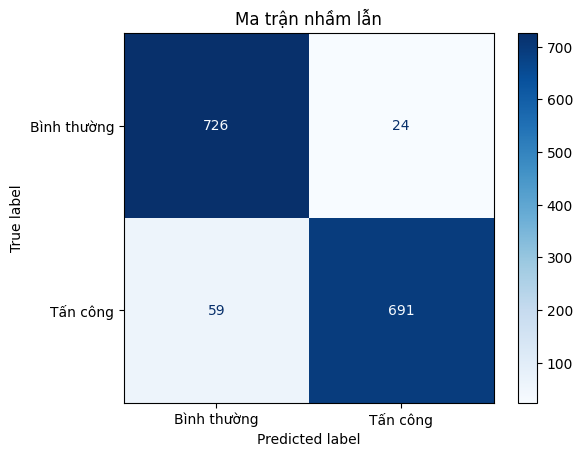

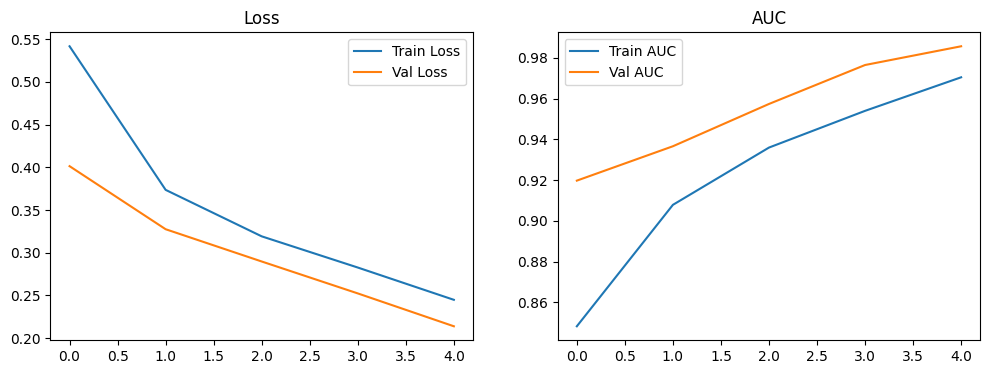

In [16]:

# ═══════════════════════════════════════════════════════════════════════════════
# 9. TEST SET EVALUATION
# ═══════════════════════════════════════════════════════════════════════════════
y_test_prob = stacking_model.predict(
    [X_test_seq, xgb_proba_test], batch_size=BATCH_SIZE
).ravel()
y_test_pred = (y_test_prob >= best_thresh).astype(int)

acc = accuracy_score(y_test, y_test_pred)
bal_acc = balanced_accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred)
rec = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)
auc = roc_auc_score(y_test, y_test_prob)

print("\n" + "=" * 60)
print("STACKING MODEL (XGBoost + SimpleRNN) - TEST RESULTS")
print("=" * 60)
print(f"Accuracy         : {acc:.4f}")
print(f"Balanced Accuracy: {bal_acc:.4f}")
print(f"Precision        : {prec:.4f}")
print(f"Recall           : {rec:.4f}")
print(f"F1-score         : {f1:.4f}")
print(f"AUC              : {auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test, y_test_pred, target_names=["Benign (0)", "Attack (1)"], digits=4
    )
)

cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()
print(f"\nConfusion Matrix:\n{cm}")
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# Vẽ ma trận nhầm lẫn
plt.rcParams["font.sans-serif"] = [
    "Arial Unicode MS",
    "DejaVu Sans",
    "SimHei",
    "sans-serif",
]
plt.rcParams["axes.unicode_minus"] = False
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=["Bình thường", "Tấn công"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Ma trận nhầm lẫn")
plt.show()

# Vẽ đường cong học
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history.history["auc"], label="Train AUC")
axes[1].plot(history.history["val_auc"], label="Val AUC")
axes[1].set_title("AUC")
axes[1].legend()
plt.show()